# Example: A Covered Call Fund on SPY
In this example, we simulate a fund that owns shares of `SPY`, the ETF that tracks the S&P 500, and sells a one-month covered call on them every month, in the style of covered call funds such as JEPI. We compare the fund's one-year growth rate with that of simply holding the shares. This is a simplified version of such a fund: we ignore dividends and early exercise and reinvest everything, while real funds such as JEPI choose their own stocks and calls.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Simulate monthly share prices:__ Simulate one year of monthly share prices with geometric Brownian motion, using the drift and volatility estimated from historical data.
> * __Price and roll a covered call:__ Price a one-month out-of-the-money American call on the binomial tree at the start of each month, and compute the fund's growth when the call expires worthless or is exercised.
> * __Compare the covered call fund with holding the shares:__ Compare the distributions of one-year growth rates, and explain how the premiums cushion losses and the sold calls give up gains.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
We'll simulate the share price with geometric Brownian motion (GBM). Let's load the single asset geometric Brownian motion (SAGBM) parameters which we estimated a few lectures ago, which include the drift and volatility for each ticker. We'll store this data in the `parameters_df::DataFrame` variable:

In [2]:
parameters_df = let

    # load the GBM parameters estimated from the 2014 to 2024 training data, one row per ticker -
    df = CSV.read(joinpath(_PATH_TO_DATA, "SAGBM-Parameters-Fall-2025.csv"), DataFrame);

    # return -
    df
end;

### Constants
Next, let's set the constants. Every parameter of the example is set here, so you can change the ticker, the strike of the calls we sell, the number of months, or the number of simulated paths and rerun the notebook. See the comments next to the constants for definitions, units, and permissible values.

In [3]:
# the shares the fund holds, and the simulation -
ticker = "SPY"; # ticker of the shares the fund holds (any ticker in parameters_df works)
Sₒ = 100.0; # share price when the fund opens (USD/share); the returns do not depend on it
number_of_months = 12; # how long we run the fund (months); we sell one call per month
number_of_paths = 10000; # number of simulated share price paths
Δt = 1/12; # one month, the life of each call (years)
random_seed = 5660; # fix the random numbers, so every run gives the same paths

# the calls the fund sells at the start of each month -
moneyness = 1.02; # strike over the share price at the start of the month, K/S (1.00 = at the money)
σ_scale = 1.0; # price the calls at this multiple of the historical volatility (try 1.2 for a higher implied volatility)
h = 60; # number of steps in the binomial tree that prices each call

# the risk-free rate, from the 13-week Treasury bill -
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-26, U.S. Treasury Daily Treasury Bill Rates
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)
𝒟 = exp(gᵧ*Δt); # accumulation factor over one month (dimensionless)

# checks -
@assert moneyness > 0 "the strike must be positive, so moneyness = K/S must be positive"
@assert number_of_months ≥ 1 && number_of_paths ≥ 1 "we need at least one month and one path"

Finally, let's look up the drift and the volatility for our ticker. As in the earlier examples, the `drift` column is the mean growth rate $\hat{\mu}_{g}$, so the GBM drift is $\hat{\mu}=\hat{\mu}_{g}+\hat{\sigma}^{2}/2$:

In [4]:
μ̂, σ̂ = let

    # initialize: the row of parameters_df for our ticker -
    row = only(eachrow(filter(:ticker => ==(ticker), parameters_df))); # fails if the ticker is missing
    μ̂_g = row.drift; # mean growth rate (1/yr)
    σ̂ = row.volatility; # historical volatility (1/sqrt(yr))
    μ̂ = μ̂_g + σ̂^2/2; # GBM drift (1/yr)

    # show the parameters -
    println("$(ticker): μ̂_g = $(round(μ̂_g, digits = 4)), σ̂ = $(round(σ̂, digits = 4)), μ̂ = $(round(μ̂, digits = 4)) (1/yr)");
    println("risk-free rate gᵧ = $(round(gᵧ, digits = 4)) (1/yr), monthly accumulation factor 𝒟 = $(round(𝒟, digits = 5))");

    # checks -
    @assert σ̂ > 0 "the volatility must be positive"

    # return -
    (μ̂, σ̂)
end;

SPY: μ̂_g = 0.1031, σ̂ = 0.1351, μ̂ = 0.1123 (1/yr)
risk-free rate gᵧ = 0.0413 (1/yr), monthly accumulation factor 𝒟 = 1.00345


___

## Task 1: Simulate Monthly Share Prices
In this task, we simulate the share price at the start of each month for one year. We use geometric Brownian motion with our historical drift $\hat{\mu}$ and volatility $\hat{\sigma}$, so these paths are our belief about the share price, not the risk-neutral probabilities.

The [sample(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyGeometricBrownianMotionEquityModel,%20NamedTuple}) returns one row per month and one column per path, with the time in the first column. We keep the share prices and store them in the `share_prices::Array{Float64,2}` variable: row $j$ holds the share price $S_{j}$ at the start of month $j$, and the last row holds the share price at the end of the year.

In [5]:
share_prices = let

    # initialize: the GBM model of the share price under our belief -
    Random.seed!(random_seed); # reproducible paths
    model = build(MyGeometricBrownianMotionEquityModel, (
        μ = μ̂, # drift (1/yr)
        σ = σ̂ # volatility (1/sqrt(yr))
    ));

    # simulate monthly prices from today to the end of the year -
    paths = VLQuantitativeFinancePackage.sample(model, (
        T₁ = 0.0, # start time (years)
        T₂ = number_of_months*Δt, # end time (years)
        Δt = Δt, # one month (years)
        Sₒ = Sₒ # share price today (USD/share)
    ), number_of_paths = number_of_paths); # rows are months; column 1 is the time, columns 2:end are the paths
    S = paths[:, 2:end]; # drop the time column: S[j, p] is the share price on path p at the start of month j

    # checks: one row per month plus the end of the year, one column per path, positive prices -
    @assert size(S) == (number_of_months + 1, number_of_paths) "unexpected size of the share price array"
    @assert all(S .> 0) "GBM share prices must be positive"

    # return -
    S
end;

`Unhide` the code block below to see how we plotted the first 50 simulated share price paths.

> __What do we see?__ Every path starts at the same share price. The spread of the paths grows with time, and some paths finish the year well below the starting price while others finish well above it. These are the outcomes the covered call fund and the shares will face.

What do the simulated share prices look like?

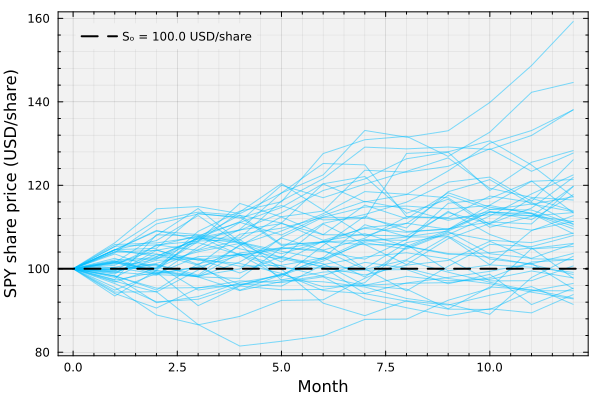

In [6]:
let

    # initialize: the months on the x-axis and how many paths to draw -
    months = 0:number_of_months; # month index (0 = today)
    number_to_plot = min(50, number_of_paths); # draw at most 50 paths, so the plot stays readable

    # plot: each column of share_prices is one path -
    plot(months, share_prices[:, 1:number_to_plot], lw = 1, c = :deepskyblue1, alpha = 0.5, label = "",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true)
    hline!([Sₒ], lw = 2, c = :black, ls = :dash, label = "Sₒ = $(Sₒ) USD/share") # the starting share price

    # labels -
    xlabel!("Month", fontsize = 18)
    ylabel!("$(ticker) share price (USD/share)", fontsize = 18)
end

___

## Task 2: Price and Roll the Covered Call
In this task, we run the fund month by month. At the start of each month, the fund owns its shares and sells one call per share. At the end of the month, the call either expires worthless or is exercised, and the fund sells a new call for the next month.

At the start of month $j$, with share price $S_{j}$:
* __Strike:__ the fund sells a one-month call with strike $K_{j}=\text{moneyness}\cdot S_{j}$, so `moneyness = 1.02` sells the call 2% out of the money.
* __Premium:__ we price the American call on the CRR binomial tree with [the binomial_premium(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.binomial_premium), using the risk-free rate $g_{y}$ and the volatility $\hat{\sigma}$ (times `σ_scale`). The fund collects $\mathcal{P}_{c,j}$ per share and holds it as cash until the end of the month.
* __End of the month:__ the fund's shares are worth $S_{j+1}$, and it owes the call's payoff $(S_{j+1}-K_{j})^{+}$.

So, as in the lecture's covered call, the fund's wealth $W$ grows over month $j$ by:
$$
\frac{W_{j+1}}{W_{j}} = \frac{S_{j+1}-\left(S_{j+1}-K_{j}\right)^{+}+\mathcal{D}_{T,0}(g_{y})\cdot\mathcal{P}_{c,j}}{S_{j}} = \frac{\min\left(S_{j+1},K_{j}\right)+\mathcal{D}_{T,0}(g_{y})\cdot\mathcal{P}_{c,j}}{S_{j}}
$$
where $T$ is one month. If we only hold the shares, wealth grows by $S_{j+1}/S_{j}$. We reinvest everything each month. We store the monthly ratios in the `fund_ratio::Array{Float64,2}` and `share_ratio::Array{Float64,2}` variables, and the premiums in the `premiums::Array{Float64,2}` variable:

In [7]:
fund_ratio, share_ratio, premiums = let

    # initialize: one row per month, one column per path -
    fund_ratio = zeros(number_of_months, number_of_paths); # W_{j+1}/W_j for the covered call fund
    share_ratio = zeros(number_of_months, number_of_paths); # S_{j+1}/S_j for the shares alone
    premiums = zeros(number_of_months, number_of_paths); # premium collected at the start of each month (USD/share)

    # main loop: every month on every path -
    for p ∈ 1:number_of_paths
        for j ∈ 1:number_of_months

            # the share price at the start and at the end of month j -
            S_start = share_prices[j, p]; # S_j (USD/share)
            S_end = share_prices[j + 1, p]; # S_{j+1} (USD/share)

            # the call we sell at the start of the month -
            K = moneyness*S_start; # strike price (USD/share)
            call = build(MyAmericanCallContractModel, (K = K, sense = -1, copy = 1, premium = 0.0)); # one short call
            𝒫 = binomial_premium(call; method = :crr, h = h, T = Δt, σ = σ_scale*σ̂, Sₒ = S_start, μ = gᵧ); # premium (USD/share)

            # the fund at the end of the month: the shares, minus the call payoff, plus the premium grown for one month -
            fund_ratio[j, p] = (min(S_end, K) + 𝒟*𝒫)/S_start; # W_{j+1}/W_j
            share_ratio[j, p] = S_end/S_start; # shares alone
            premiums[j, p] = 𝒫; # store the premium
        end
    end

    # checks: the fund gives up the gains above the strike, and the premium is positive -
    @assert all(premiums .> 0) "every call premium should be positive"
    @assert all(fund_ratio .≤ moneyness .+ 𝒟 .* premiums ./ share_prices[1:end-1, :] .+ 1e-12) "the fund's monthly ratio is capped at moneyness plus the premium"

    # return -
    (fund_ratio, share_ratio, premiums)
end;

Let's follow the first path month by month. For each month, the table shows the share price at the start and the end, the strike, the premium (also as a percentage of the share price), whether the call was exercised, and the ratios $W_{j+1}/W_{j}$ for the fund and $S_{j+1}/S_{j}$ for the shares:

In [8]:
let

    # initialize: the first simulated path -
    p = 1; # path index
    S_start = share_prices[1:end-1, p]; # share price at the start of each month (USD/share)
    S_end = share_prices[2:end, p]; # share price at the end of each month (USD/share)
    K = moneyness .* S_start; # strike of each month's call (USD/share)

    # build the table: one row per month -
    df = DataFrame(
        month = 1:number_of_months,
        S_start = S_start,
        K = K,
        premium = premiums[:, p],
        premium_percent = 100 .* premiums[:, p] ./ S_start, # premium as a percentage of the share price
        S_end = S_end,
        exercised = S_end .> K, # true if the call finishes in the money
        fund = fund_ratio[:, p],
        shares = share_ratio[:, p]
    );

    # show the table -
    pretty_table(df; column_labels = ["month", "S start", "K", "premium", "premium (%)", "S end", "exercised", "fund W(j+1)/W(j)", "shares S(j+1)/S(j)"],
        formatters = [fmt__printf("%.2f", [2, 3, 4, 5, 6]), fmt__printf("%.4f", [8, 9])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 ------- --------- -------- --------- ------------- -------- ----------- ------------------ --------------------
  month   S start        K   premium   premium (%)    S end   exercised   fund W(j+1)/W(j)   shares S(j+1)/S(j) 
 ------- --------- -------- --------- ------------- -------- ----------- ------------------ --------------------
      1    100.00   102.00      0.87          0.87    99.66       false             1.0054               0.9966
      2     99.66   101.65      0.87          0.87   101.30       false             1.0252               1.0164
      3    101.30   103.32      0.89          0.87   104.06        true             1.0288               1.0273
      4    104.06   106.15      0.91          0.87   106.09       false             1.0282               1.0194
      5    106.09   108.21      0.93          0.87   101.62       false             0.9666               0.9579
      6    101.62   103.65      0.89          0.87   106.64        true             1.0288           

> __What do we see?__
>
> * __The premium:__ The strike is a fixed multiple of the share price, so the premium is the same percentage of the share price every month.
> * __Months the call is exercised:__ The share price finished above the strike, so the fund's ratio $W_{j+1}/W_{j}$ stops at `moneyness` plus the premium (grown for one month) as a fraction of the share price. The shares grow more only when they rise beyond that level.
> * __Months the call expires worthless:__ The fund keeps the shares and the premium, so its ratio is above that of the shares by the premium (grown for one month) as a fraction of the share price.

Your table will differ if you change the constants.
___

## Task 3: Compare One-Year Growth Rates
In this task, we compare the fund with holding the shares over the whole year. As for a share price, the one-year growth rate of the fund's wealth is the log of the ratio of the final and initial wealth, divided by the time; it is the sum of the monthly log ratios:
$$
g = \frac{1}{T}\ln\left(\frac{W_{N+1}}{W_{1}}\right) = \frac{1}{T}\sum_{j=1}^{N}\ln\left(\frac{W_{j+1}}{W_{j}}\right)
$$
where $N$ is the number of months and $T=N\Delta t$ (years). The same formula with the share prices gives the growth rate of the shares. We compute $g$ (units: 1/yr) for the fund and for the shares on every path, and summarize the two distributions: the mean, the standard deviation, three percentiles, the probability of losing money ($g<0$), and the probability that the fund grows faster than the shares.

In [9]:
fund_g, share_g = let

    # initialize: the one-year growth rate on every path, the sum of the monthly log ratios divided by the time -
    T = number_of_months*Δt; # length of the simulation (years)
    fund_g = vec(sum(log.(fund_ratio), dims = 1)) ./ T; # covered call fund (1/yr)
    share_g = vec(sum(log.(share_ratio), dims = 1)) ./ T; # shares alone (1/yr)

    # summarize each distribution -
    summary(g) = [mean(g), std(g), quantile(g, 0.05), median(g), quantile(g, 0.95), mean(g .< 0)]; # statistics of a set of growth rates
    df = DataFrame(
        statistic = ["mean", "standard deviation", "5th percentile", "median", "95th percentile", "probability of a loss, g < 0"],
        fund = summary(fund_g),
        shares = summary(share_g)
    );

    # show the results -
    pretty_table(df; column_labels = ["one-year growth rate (1/yr)", "covered call fund", "$(ticker) shares"],
        alignment = [:l, :r, :r], formatters = [fmt__printf("%.4f", [2, 3])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
    println("Probability that the fund grows faster than the shares: $(round(mean(fund_g .> share_g), digits = 4))");
    down = share_g .< 0; # paths where the shares lose money over the year
    println("When the shares lose money, probability that the fund grows faster: $(round(mean(fund_g[down] .> share_g[down]), digits = 4))");
    println("Average premium collected per month: $(round(100*mean(premiums ./ share_prices[1:end-1, :]), digits = 3))% of the share price");

    # checks: one growth rate per path for each -
    @assert length(fund_g) == number_of_paths && length(share_g) == number_of_paths "one growth rate per path"

    # return -
    (fund_g, share_g)
end;

 ------------------------------ ------------------- ------------
  one-year growth rate (1/yr)    covered call fund   SPY shares 
 ------------------------------ ------------------- ------------
  mean                                      0.0802       0.1018
  standard deviation                        0.0915       0.1358
  5th percentile                           -0.0799      -0.1226
  median                                    0.0856       0.1022
  95th percentile                           0.2215       0.3259
  probability of a loss, g < 0              0.1871       0.2261
 ------------------------------ ------------------- ------------
Probability that the fund grows faster than the shares: 0.4114
When the shares lose money, probability that the fund grows faster: 0.8651
Average premium collected per month: 0.875% of the share price


> __What do we see?__
>
> * __Spread:__ The fund's growth rates have a smaller standard deviation, and its 5th and 95th percentiles sit closer together than those of the shares. The premiums lift the bad years, and the sold calls cut off the best years.
> * __Losses and gains:__ The fund is less likely to lose money over the year, but its 95th percentile is far below that of the shares. Compare the two means: the premiums do not make up for all the gains the calls give up.

`Unhide` the code block below to see how we plotted the two distributions of one-year growth rates.

> __What do we see?__ The fund's distribution (red) is narrower than that of the shares (blue). Its left tail is shifted to the right by the premiums, and its right tail stops well short of the shares' right tail.

How do the two distributions compare?

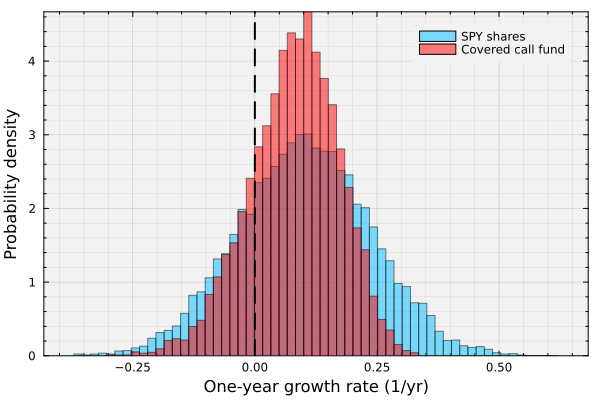

In [10]:
let

    # initialize: common bins, so the two histograms are comparable -
    lo = minimum([fund_g; share_g]); # smallest growth rate on any path (1/yr)
    hi = maximum([fund_g; share_g]); # largest growth rate on any path (1/yr)
    bins = range(lo, stop = hi, length = 60); # bin edges (1/yr)

    # plot: the two distributions of one-year growth rates -
    histogram(share_g, bins = bins, normalize = :pdf, c = :deepskyblue1, alpha = 0.5, label = "$(ticker) shares",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true)
    histogram!(fund_g, bins = bins, normalize = :pdf, c = :red, alpha = 0.5, label = "Covered call fund")
    vline!([0.0], lw = 2, c = :black, ls = :dash, label = "") # zero growth: no gain, no loss

    # labels -
    xlabel!("One-year growth rate (1/yr)", fontsize = 18)
    ylabel!("Probability density", fontsize = 18)
end

Finally, let's plot the fund's one-year growth rate against the growth rate of the shares on the same path. Each point is one simulated year.

> __What do we see?__ When the shares fall, most points sit above the dashed line: the fund usually loses less, but not always (see the printout above), because a call can cap a month's gain before later months lose. When the shares grow quickly, the points bend below the line and level off: the fund gives up much of the gain. This is the shape of the covered call profit diagram from the lecture, repeated over a year of monthly calls. For the same growth rate of the shares, the fund's growth rate still varies, because each month's call depends on that month's move, not only on the year's.

How does the fund's growth rate depend on the growth rate of the shares?

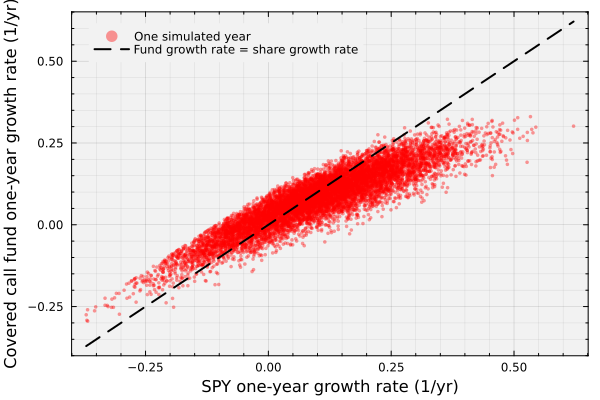

In [11]:
let

    # initialize: the range of the shares' growth rates, for the dashed line where the fund equals the shares -
    x = [minimum(share_g), maximum(share_g)]; # endpoints of the line (1/yr)

    # plot: one point per path -
    scatter(share_g, fund_g, ms = 2, c = :red, msw = 0, alpha = 0.4, label = "One simulated year",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft)
    plot!(x, x, lw = 2, c = :black, ls = :dash, label = "Fund growth rate = share growth rate") # where the two growth rates are equal

    # labels -
    xlabel!("$(ticker) one-year growth rate (1/yr)", fontsize = 18)
    ylabel!("Covered call fund one-year growth rate (1/yr)", fontsize = 18)
end

Your numbers will differ if you change the constants. Try `moneyness = 1.00` (at-the-money calls, more premium, less upside), `moneyness = 1.05`, or `σ_scale = 1.2`.
___

## Summary
In this example, we simulated a fund that owns shares and sells a one-month covered call every month, and compared its one-year growth rate with that of holding the shares.

> __Key Takeaways:__
>
> * __Monthly share prices from geometric Brownian motion:__ We simulated a year of monthly share prices with the drift and volatility estimated from historical data. These paths are our belief about the share price, and they give the range of outcomes the fund faces.
> * __A covered call fund rolls the lecture's covered call:__ Each month we priced an out-of-the-money American call on the binomial tree and computed the fund's growth from the shares, the call payoff, and the premium grown to the end of the month. When the call was exercised, the fund's growth stopped at the strike plus the premium grown for one month.
> * __Covered call funds trade upside for a cushion:__ Over the year, the fund's growth rates were less spread out and less likely to be negative, but its best years were far below those of the shares. Plotting the fund's growth rate against that of the shares showed a shape like the covered call profit diagram.

Funds such as JEPI and JEPQ sell covered calls on a large scale; this example shows the trade-off their investors accept.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___